# Stream A — Results (Updated — NC included)

NC id-collision is fixed (composite keys). NC now has valid clip_sim + VG features.

**Evaluated:** VERITE (1,001) + MMFakeBench (10,000) + NewsCLIPpings test (3,632)

**Order:** `entity_scorer` → **`stream_a_results`** → `03_stream_b/clip_features`

**Fixed:** `stream_a_lr` is trained once on NewsCLIP train, then evaluated zero-shot on NC test, VERITE, and MMFake instead of using target-dataset random splits.

## 1. Setup

In [1]:
import sys, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, confusion_matrix, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path('../../').resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style='whitegrid', font_scale=1.1)
C_OOC='#E05A4B'; C_GENUINE='#4B8AE0'; C_GREY='#BBBBBB'; C_AMBER='#F0A500'; C_GREEN='#2ECC71'

FEAT_CACHE   = CACHE / 'entity_scorer'
PAPER_FIGS   = ROOT  / 'paper' / 'figures'
PAPER_TABLES = ROOT  / 'paper' / 'tables'
for d in [PAPER_FIGS, PAPER_TABLES]: d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    p = PAPER_FIGS / f'{name}.png'
    plt.savefig(p, bbox_inches='tight', dpi=150)
    print(f'  Saved -> {p.relative_to(ROOT)}')

def savecsv(df, name):
    p = PAPER_TABLES / f'{name}.csv'
    df.to_csv(p, index=False)
    print(f'  Saved -> {p.relative_to(ROOT)}')

print('Setup done.')

Setup done.


## 2. Load features and labels

In [2]:
verite_feats = pickle.load(open(FEAT_CACHE/'features_verite.pkl','rb'))
mmfake_feats = pickle.load(open(FEAT_CACHE/'features_mmfake.pkl','rb'))
nc_train_feats = pickle.load(open(FEAT_CACHE/'features_newsclippings_train.pkl','rb'))
nc_test_feats = pickle.load(open(FEAT_CACHE/'features_newsclippings_test.pkl','rb'))

def bin_label(v):
    return 1 if str(v).strip().lower() in ('1','true','out-of-context') else 0

# VERITE labels
verite_csv = pd.read_csv(VERITE/'VERITE.csv')
verite_csv['label'] = verite_csv['label'].apply(bin_label)
verite_labels = {f'verite_{i}': int(r['label']) for i,r in verite_csv.iterrows()}

# MMFake labels
raw = load_json(DATA/'mmfakebench'/'MMFakeBench_test.json')
mm_list = raw if isinstance(raw,list) else list(raw.values())
mmfake_labels = {f'mmfake_{i}': int(str(p.get('gt_answers','')).lower()=='fake')
                 for i,p in enumerate(mm_list)}

# NC train/test labels (composite key)
def load_nc_pairs(path):
    raw = load_json(path)
    return raw.get('annotations', raw) if isinstance(raw, dict) else raw

nc_train_pairs = load_nc_pairs(NEWSCLIP/'train.json')
nc_test_pairs  = load_nc_pairs(NEWSCLIP/'test.json')
nc_train_labels = {f'{row["id"]}_{int(row["falsified"])}': int(row['falsified'])
                   for row in nc_train_pairs}
nc_test_labels = {f'{row["id"]}_{int(row["falsified"])}': int(row['falsified'])
                  for row in nc_test_pairs}

def build_df(feats, labels, ds_name):
    rows = []
    for pid, f in feats.items():
        lbl = labels.get(pid,-1)
        if lbl >= 0: rows.append({'pid':pid,'dataset':ds_name,'label':lbl,**f})
    return pd.DataFrame(rows)

v_df  = build_df(verite_feats,  verite_labels,  'verite')
mm_df = build_df(mmfake_feats,  mmfake_labels,  'mmfake')
nc_train_df = build_df(nc_train_feats, nc_train_labels, 'newsclippings_train')
nc_df = build_df(nc_test_feats, nc_test_labels, 'newsclippings')
df    = pd.concat([v_df, mm_df, nc_df], ignore_index=True)

print(f'  VERITE  : {len(v_df):,}  OOC={v_df["label"].mean()*100:.1f}%')
print(f'  MMFake  : {len(mm_df):,}  OOC={mm_df["label"].mean()*100:.1f}%')
print(f'  NC train: {len(nc_train_df):,}  OOC={nc_train_df["label"].mean()*100:.1f}%')
print(f'  NC test : {len(nc_df):,}  OOC={nc_df["label"].mean()*100:.1f}%')
print(f'  Total   : {len(df):,}')

# Validate NC labels are now balanced (~50/50)
if abs(nc_df['label'].mean() - 0.5) > 0.05:
    print(f'  WARNING: NC OOC ratio is {nc_df["label"].mean()*100:.1f}% (expected ~50%)')
    print('  Check that composite keys are being used in NER/entity_scorer caches')
else:
    print('  NC label distribution looks correct (~50% OOC)')

  VERITE  : 1,001  OOC=66.2%
  MMFake  : 10,000  OOC=70.0%
  NC train: 71,072  OOC=50.0%
  NC test : 7,264  OOC=50.0%
  Total   : 18,265
  NC label distribution looks correct (~50% OOC)


## 3. Helpers

In [3]:
feature_names = ['n_entities','max_grounding','min_grounding','mean_grounding',
                 'person_max','gpe_max','org_max','clip_sim']

def evaluate(y_true, y_pred, y_score=None):
    m = {'acc':round(accuracy_score(y_true,y_pred)*100,2),
         'f1': round(f1_score(y_true,y_pred,zero_division=0)*100,2),
         'prec':round(precision_score(y_true,y_pred,zero_division=0)*100,2),
         'rec': round(recall_score(y_true,y_pred,zero_division=0)*100,2)}
    if y_score is not None and len(np.unique(y_true))==2:
        try: m['auroc'] = round(roc_auc_score(y_true,y_score)*100,2)
        except: m['auroc'] = np.nan
    return m

def best_threshold_predict(y_true, scores, n=300):
    ts = np.linspace(scores.min(), scores.max(), n)
    best_acc, best_t = 0, ts[0]
    for t in ts:
        pred = (scores < t).astype(int)
        if (pred==y_true).mean() > best_acc: best_acc, best_t=(pred==y_true).mean(),t
    return (scores < best_t).astype(int), best_t

print('Helpers ready.')

Helpers ready.


## 4. Evaluate all 3 datasets

In [4]:

all_results = []

def add_single_dataset_results(subset_df, ds_label):
    sub = subset_df.copy().reset_index(drop=True)
    y = sub['label'].values
    if len(y) == 0 or len(np.unique(y)) < 2:
        print(f'  {ds_label}: skipped (no valid labels)')
        return

    majority = int(y.mean() > 0.5)
    all_results.append({'method':'majority_class','dataset':ds_label,
                         **evaluate(y, np.full_like(y, majority))})

    for f in ['clip_sim','max_grounding','person_max']:
        if f not in sub.columns:
            continue
        s = sub[f].fillna(sub[f].median()).values
        if np.all(np.isnan(s)) or np.nanstd(s) == 0:
            continue
        pred, t = best_threshold_predict(y, s)
        m = evaluate(y, pred, -s)
        all_results.append({'method':f'threshold_{f}','dataset':ds_label, **m})
        print(f'  {ds_label:<15} {f:<22} t={t:.3f}  acc={m["acc"]}%  auroc={m.get("auroc","N/A")}%')

# Majority and simple threshold baselines can be reported per dataset.
for subset_df, ds_label in [(v_df,'verite'),(mm_df,'mmfake'),(nc_df,'newsclippings')]:
    add_single_dataset_results(subset_df, ds_label)
    print()

# Stream A LR: fit once on NewsCLIP train only, then evaluate zero-shot on NC test + VERITE + MMFake.
feat_cols = [f for f in feature_names if f in nc_train_df.columns and nc_train_df[f].notna().sum() > 50]
print(f'LR feature columns: {feat_cols}')

if len(feat_cols) >= 2:
    X_train = nc_train_df[feat_cols].fillna(0).values
    y_train = nc_train_df['label'].values
    pipe = Pipeline([('sc',StandardScaler()),('lr',LogisticRegression(max_iter=500,C=1.0,random_state=42))])
    pipe.fit(X_train, y_train)

    for subset_df, ds_label in [(nc_df,'newsclippings'), (v_df,'verite'), (mm_df,'mmfake')]:
        sub = subset_df.copy().reset_index(drop=True)
        y = sub['label'].values
        X = sub[feat_cols].fillna(0).values
        pred_lr = pipe.predict(X)
        prob_lr = pipe.predict_proba(X)[:,1]
        m = evaluate(y, pred_lr, prob_lr)
        all_results.append({'method':'stream_a_lr','dataset':ds_label, **m})
        print(f'  {ds_label:<15} LR trained on NC train  acc={m["acc"]}%  auroc={m.get("auroc","N/A")}%')
else:
    print('Not enough feature columns for Stream A LR.')


  verite          clip_sim               t=0.350  acc=66.33%  auroc=59.77%
  verite          max_grounding          t=0.332  acc=66.33%  auroc=50.78%
  verite          person_max             t=0.267  acc=66.13%  auroc=51.07%

  mmfake          clip_sim               t=0.388  acc=70.0%  auroc=48.9%
  mmfake          max_grounding          t=0.388  acc=70.0%  auroc=48.9%
  mmfake          person_max             t=0.360  acc=69.99%  auroc=49.6%

  newsclippings   clip_sim               t=0.297  acc=65.9%  auroc=71.97%
  newsclippings   max_grounding          t=0.273  acc=59.44%  auroc=62.11%
  newsclippings   person_max             t=0.274  acc=55.31%  auroc=57.39%

LR feature columns: ['n_entities', 'max_grounding', 'min_grounding', 'mean_grounding', 'person_max', 'gpe_max', 'org_max', 'clip_sim']
  newsclippings   LR trained on NC train  acc=66.08%  auroc=72.77%
  verite          LR trained on NC train  acc=55.74%  auroc=58.93%
  mmfake          LR trained on NC train  acc=63.95%  auroc

## 5. Results table

In [5]:
results_df = pd.DataFrame(all_results)
print('Stream A -- Full Results:')
print(results_df.to_string(index=False))
savecsv(results_df, 'stream_a_results')

# vs-baseline
comp_rows = []
for ds in ['verite','mmfake','newsclippings']:
    sub_r = results_df[results_df['dataset']==ds]
    if sub_r.empty: continue
    base = sub_r[sub_r['method']=='majority_class']
    best = sub_r[sub_r['method']=='stream_a_lr']
    if base.empty or best.empty: continue
    comp_rows.append({'dataset':ds,
                      'majority_acc':  base['acc'].values[0],
                      'stream_a_acc':  best['acc'].values[0],
                      'acc_gain':      round(best['acc'].values[0]-base['acc'].values[0],2),
                      'stream_a_auroc':best['auroc'].values[0] if 'auroc' in best.columns else np.nan})
comp_df = pd.DataFrame(comp_rows)
print('\nStream A vs Baseline:')
print(comp_df.to_string(index=False))
savecsv(comp_df, 'stream_a_vs_baseline')

Stream A -- Full Results:
                 method       dataset   acc    f1  prec    rec  auroc
         majority_class        verite 66.23 79.69 66.23 100.00    NaN
     threshold_clip_sim        verite 66.33 78.76 67.64  94.27  59.77
threshold_max_grounding        verite 66.33 79.74 66.30 100.00  50.78
   threshold_person_max        verite 66.13 79.62 66.20  99.85  51.07
         majority_class        mmfake 70.00 82.35 70.00 100.00    NaN
     threshold_clip_sim        mmfake 70.00 82.35 70.00  99.99  48.90
threshold_max_grounding        mmfake 70.00 82.35 70.00  99.99  48.90
   threshold_person_max        mmfake 69.99 82.33 70.03  99.87  49.60
         majority_class newsclippings 50.00  0.00  0.00   0.00    NaN
     threshold_clip_sim newsclippings 65.90 66.41 65.43  67.43  71.97
threshold_max_grounding newsclippings 59.44 62.87 57.97  68.67  62.11
   threshold_person_max newsclippings 55.31 63.16 53.73  76.60  57.39
            stream_a_lr newsclippings 66.08 64.82 67.32  62.50  

## 6. Summary bar chart

  Saved -> paper\figures\stream_a_summary_bar.png


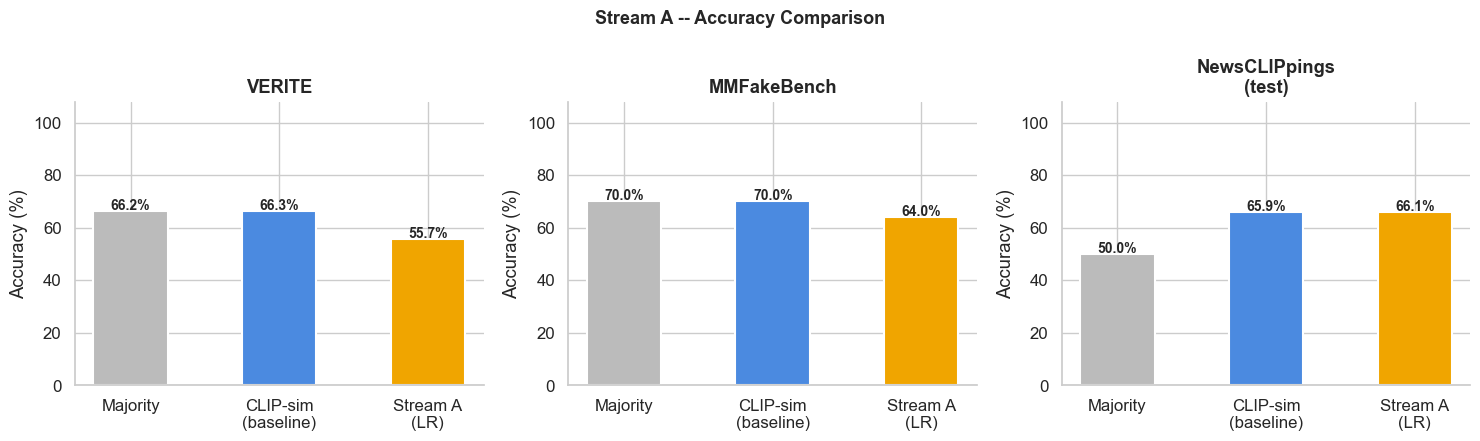

In [6]:
datasets_show = [('VERITE',v_df,results_df[results_df['dataset']=='verite']),
                 ('MMFakeBench',mm_df,results_df[results_df['dataset']=='mmfake']),
                 ('NewsCLIPpings\n(test)',nc_df,results_df[results_df['dataset']=='newsclippings'])]

fig, axes = plt.subplots(1, len(datasets_show), figsize=(5*len(datasets_show), 4.5))

for ax, (ds_label, _, res_sub) in zip(axes, datasets_show):
    methods = ['majority_class','threshold_clip_sim','stream_a_lr']
    labels  = ['Majority','CLIP-sim\n(baseline)','Stream A\n(LR)']
    colors  = [C_GREY, C_GENUINE, C_AMBER]
    accs = []
    for m in methods:
        row = res_sub[res_sub['method']==m]
        accs.append(float(row['acc'].values[0]) if not row.empty else 0)
    bars = ax.bar(labels, accs, color=colors, edgecolor='white', linewidth=1.5, width=0.5)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                f'{bar.get_height():.1f}%', ha='center', fontsize=10, fontweight='bold')
    ax.set_ylim(0, 108)
    ax.set_title(ds_label, fontweight='bold')
    ax.set_ylabel('Accuracy (%)')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.suptitle('Stream A -- Accuracy Comparison', fontweight='bold', fontsize=13)
plt.tight_layout(); savefig('stream_a_summary_bar'); plt.show()

## 7. ROC curves (VERITE + NC test)

  Saved -> paper\figures\stream_a_roc.png


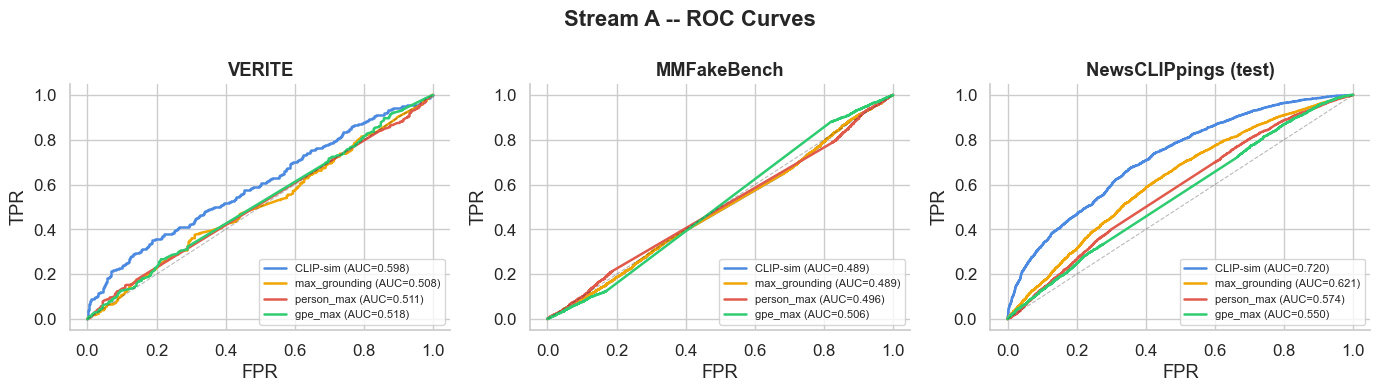

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
roc_colors = [C_GENUINE, C_AMBER, C_OOC, C_GREEN]
feat_pairs = [('clip_sim','CLIP-sim'),('max_grounding','max_grounding'),
              ('person_max','person_max'),('gpe_max','gpe_max')]

for ax, (subset, y_true, label) in zip(axes, [
    (v_df, v_df['label'].values, 'VERITE'),
    (mm_df, mm_df['label'].values, 'MMFakeBench'),
    (nc_df, nc_df['label'].values, 'NewsCLIPpings (test)'),
]):
    for (f, fname), color in zip(feat_pairs, roc_colors):
        s = subset[f].fillna(subset[f].median())
        if s.isna().all() or len(np.unique(y_true))<2: continue
        try:
            fpr, tpr, _ = roc_curve(y_true, -s.values)
            auc = roc_auc_score(y_true, -s.values)
            ax.plot(fpr, tpr, color=color, linewidth=1.8, label=f'{fname} (AUC={auc:.3f})')
        except: pass
    ax.plot([0,1],[0,1],'k--',alpha=0.3,linewidth=0.8)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.legend(fontsize=8, loc='lower right')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.suptitle('Stream A -- ROC Curves', fontweight='bold')
plt.tight_layout(); savefig('stream_a_roc'); plt.show()

## 8. Feature correlation heatmap

  Saved -> paper\figures\stream_a_feature_heatmap.png


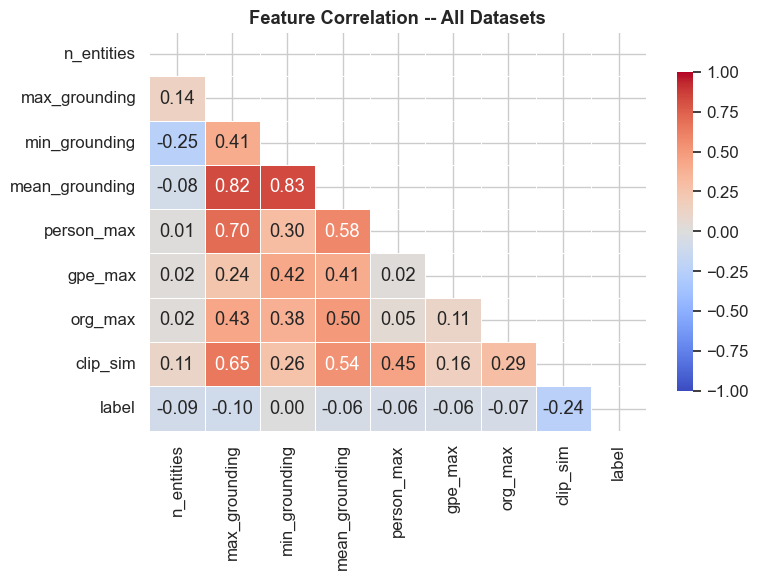

Correlation with OOC label (all datasets):
  clip_sim               -0.2360
  max_grounding          -0.0984
  n_entities             -0.0927
  org_max                -0.0660
  person_max             -0.0638
  gpe_max                -0.0605
  mean_grounding         -0.0566
  min_grounding          +0.0045
  Saved -> paper\tables\stream_a_feature_label_corr.csv


In [8]:
active = df[feature_names+['label']].fillna(df[feature_names+['label']].median())
corr   = active.corr()
fig, ax = plt.subplots(figsize=(8,6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, cbar_kws={'shrink':0.8})
ax.set_title('Feature Correlation -- All Datasets', fontweight='bold')
plt.tight_layout(); savefig('stream_a_feature_heatmap'); plt.show()

label_corr = active.corr()['label'].drop('label').sort_values()
print('Correlation with OOC label (all datasets):')
for f, c in label_corr.items(): print(f'  {f:<22} {c:+.4f}')
savecsv(label_corr.reset_index().rename(columns={'index':'feature','label':'corr_with_label'}),
        'stream_a_feature_label_corr')

## 9. Done

In [9]:
print('='*60)
print('  STREAM A RESULTS (Updated -- NC included)')
print('='*60)
if not comp_df.empty:
    for _, row in comp_df.iterrows():
        print(f'  {row["dataset"]:<15} majority={row["majority_acc"]:.1f}%'
              f'  stream_a={row["stream_a_acc"]:.1f}%'
              f'  delta={row["acc_gain"]:+.1f}%'
              f'  auroc={row["stream_a_auroc"]:.1f}%')
print()
for f in sorted(PAPER_TABLES.glob('stream_a_*.csv')): print(f'  {f.name}')
for f in sorted(PAPER_FIGS.glob('stream_a_*.png')):   print(f'  {f.name}')
print()
print('  Next: notebooks/03_stream_b/clip_features.ipynb')

  STREAM A RESULTS (Updated -- NC included)
  verite          majority=66.2%  stream_a=55.7%  delta=-10.5%  auroc=58.9%
  mmfake          majority=70.0%  stream_a=64.0%  delta=-6.0%  auroc=48.2%
  newsclippings   majority=50.0%  stream_a=66.1%  delta=+16.1%  auroc=72.8%

  stream_a_feature_label_corr.csv
  stream_a_results.csv
  stream_a_verite_predictions.csv
  stream_a_vs_baseline.csv
  stream_a_confusion.png
  stream_a_feature_heatmap.png
  stream_a_roc.png
  stream_a_summary_bar.png

  Next: notebooks/03_stream_b/clip_features.ipynb
